# Find chronological splits for SciQuality labels

 Each candidate has a complete 24-hour NF-only gap, a holdout between 3% and 15%, and sufficient NF and FL images in both training and holdout.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")

# Find the repository root.
ROOT = Path.cwd().resolve()
while not (ROOT / "data_labeling").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Repository root could not be found.")
    ROOT = ROOT.parent

LABEL_FILE = ROOT / "data_labeling/data_labels/sciquality/labels_sciquality_2010_2026_binary.csv"
assert LABEL_FILE.exists(), f"File not found: {LABEL_FILE}"

In [2]:
# Load labels and recover timestamps from image paths.
data = pd.read_csv(LABEL_FILE)
timestamp_text = data["label"].str.extract(r"HMI\.m(\d{4}\.\d{2}\.\d{2}_\d{2}\.\d{2}\.\d{2})")[0]
data["timestamp"] = pd.to_datetime(timestamp_text, format="%Y.%m.%d_%H.%M.%S", errors="coerce")
data["goes_class"] = pd.to_numeric(data["goes_class"], errors="coerce")
data = data.sort_values("timestamp").reset_index(drop=True)

assert data["label"].duplicated().sum() == 0
assert data[["timestamp", "goes_class"]].isna().sum().sum() == 0
assert set(data["goes_class"].unique()) <= {0, 1}
print(f"Images loaded: {len(data):,}")

Images loaded: 128,117


## Chronological periods and major gaps

In [3]:
# Keep the previous complete-stage boundaries for a controlled comparison.
BLOCK_LIMITS = {
    "Stage 1": (pd.Timestamp("2010-12-06 07:00"), pd.Timestamp("2017-12-31 23:00")),
    "Stage 2": (pd.Timestamp("2018-01-02 00:00"), pd.Timestamp("2023-06-29 22:00")),
    "Stage 3": (pd.Timestamp("2023-07-01 00:00"), pd.Timestamp("2024-06-29 10:00")),
    "Validation": (pd.Timestamp("2024-07-01 00:00"), pd.Timestamp("2025-06-30 23:00")),
    "Test": (pd.Timestamp("2025-07-02 00:00"), pd.Timestamp("2026-07-31 23:00")),
}
MAJOR_GAPS = {
    "Stage 1 → Stage 2": (pd.Timestamp("2018-01-01 00:00"), pd.Timestamp("2018-01-01 23:00")),
    "Stage 2 → Stage 3": (pd.Timestamp("2023-06-29 23:00"), pd.Timestamp("2023-06-30 22:00")),
    "Stage 3 → Validation": (pd.Timestamp("2024-06-29 11:00"), pd.Timestamp("2024-06-30 10:00")),
    "Validation → Test": (pd.Timestamp("2025-07-01 00:00"), pd.Timestamp("2025-07-01 23:00")),
}

blocks = {name: data[data["timestamp"].between(start, end)].copy() for name, (start, end) in BLOCK_LIMITS.items()}

In [4]:
def summarize(name, frame):
    total = len(frame)
    fl = int(frame["goes_class"].sum())
    return {"dataset": name, "start": frame["timestamp"].min(), "end": frame["timestamp"].max(),
            "samples": total, "NF": total - fl, "FL": fl,
            "FL_percent": 100 * fl / total if total else np.nan}

display(pd.DataFrame([summarize(name, frame) for name, frame in blocks.items()]))

,dataset,start,end,samples,NF,FL,FL_percent
0,Stage 1,2010-12-06 07:00:00,2017-12-31 23:00:00,54892,43111,11781,21.462144
1,Stage 2,2018-01-02 00:00:00,2023-06-29 22:00:00,46800,41743,5057,10.805556
2,Stage 3,2023-07-01 00:00:00,2024-06-29 10:00:00,8648,3976,4672,54.024052
3,Validation,2024-07-01 00:00:00,2025-06-30 23:00:00,8480,3348,5132,60.518868
4,Test,2025-07-02 00:00:00,2026-07-31 23:00:00,9187,6044,3143,34.211386


In [5]:
def check_gap(name, start, end):
    gap = data[data["timestamp"].between(start, end)]
    expected = pd.date_range(start, end, freq="h")
    missing = expected.difference(gap["timestamp"])
    fl = int(gap["goes_class"].sum())
    return {"boundary": name, "start": start, "end": end, "samples": len(gap),
            "FL": fl, "missing_hours": len(missing),
            "valid_gap": len(gap) == 24 and fl == 0 and len(missing) == 0}

major_gap_summary = pd.DataFrame([check_gap(name, start, end) for name, (start, end) in MAJOR_GAPS.items()])
display(major_gap_summary)
assert major_gap_summary["valid_gap"].all()
print("All major boundaries have complete 24-hour NF-only gaps.")

,boundary,start,end,samples,FL,missing_hours,valid_gap
0,Stage 1 → Stage 2,2018-01-01 00:00:00,2018-01-01 23:00:00,24,0,0,True
1,Stage 2 → Stage 3,2023-06-29 23:00:00,2023-06-30 22:00:00,24,0,0,True
2,Stage 3 → Validation,2024-06-29 11:00:00,2024-06-30 10:00:00,24,0,0,True
3,Validation → Test,2025-07-01 00:00:00,2025-07-01 23:00:00,24,0,0,True


All major boundaries have complete 24-hour NF-only gaps.


## Check the previous internal gaps

In [6]:
PREVIOUS_INTERNAL_GAPS = {
    "Stage 1": (pd.Timestamp("2017-01-06 04:00"), pd.Timestamp("2017-01-07 03:00")),
    "Stage 2": (pd.Timestamp("2023-03-08 23:00"), pd.Timestamp("2023-03-09 22:00")),
    "Stage 3": (pd.Timestamp("2024-05-06 06:00"), pd.Timestamp("2024-05-07 05:00")),
}
previous_gap_summary = pd.DataFrame([check_gap(name, start, end) for name, (start, end) in PREVIOUS_INTERNAL_GAPS.items()])
display(previous_gap_summary)

,boundary,start,end,samples,FL,missing_hours,valid_gap
0,Stage 1,2017-01-06 04:00:00,2017-01-07 03:00:00,24,0,0,True
1,Stage 2,2023-03-08 23:00:00,2023-03-09 22:00:00,24,0,0,True
2,Stage 3,2024-05-06 06:00:00,2024-05-07 05:00:00,24,24,0,False


## Search for valid train/holdout candidates

In [7]:
def find_holdout_candidates(stage_data, target_percent=15, minimum_percent=3,
                            minimum_train_fl=500, minimum_train_nf=500,
                            minimum_holdout_fl=200, minimum_holdout_nf=200,
                            minimum_train_to_holdout_fl_ratio=1):
    """Find holdouts after complete 24-hour NF gaps using the previous logic."""
    stage_data = stage_data.sort_values("timestamp").reset_index(drop=True)
    hourly_index = pd.date_range(stage_data["timestamp"].min(), stage_data["timestamp"].max(), freq="h")
    hourly = stage_data.set_index("timestamp")["goes_class"].reindex(hourly_index)
    gap_ends = hourly.index[(hourly.rolling(24).count() == 24) & (hourly.rolling(24).sum() == 0)]
    stage_fl_percent = 100 * stage_data["goes_class"].mean()
    candidates = []

    for gap_end in gap_ends:
        gap_start = gap_end - pd.Timedelta(hours=23)
        holdout_start = gap_end + pd.Timedelta(hours=1)
        training = stage_data[stage_data["timestamp"] < gap_start]
        holdout = stage_data[stage_data["timestamp"] >= holdout_start]
        if training.empty or holdout.empty:
            continue

        train_fl = int(training["goes_class"].sum()); train_nf = len(training) - train_fl
        holdout_fl = int(holdout["goes_class"].sum()); holdout_nf = len(holdout) - holdout_fl
        holdout_percent = 100 * len(holdout) / (len(training) + len(holdout))
        enough_data = (train_fl >= minimum_train_fl and train_nf >= minimum_train_nf
                       and holdout_fl >= minimum_holdout_fl and holdout_nf >= minimum_holdout_nf
                       and train_fl >= minimum_train_to_holdout_fl_ratio * holdout_fl)
        if not enough_data or not minimum_percent <= holdout_percent <= target_percent:
            continue

        holdout_fl_percent = 100 * holdout_fl / len(holdout)
        candidates.append({"gap_start": gap_start, "gap_end": gap_end, "holdout_start": holdout_start,
            "train_samples": len(training), "train_FL": train_fl, "train_NF": train_nf,
            "holdout_samples": len(holdout), "holdout_FL": holdout_fl, "holdout_NF": holdout_nf,
            "holdout_percent": holdout_percent, "holdout_FL_percent": holdout_fl_percent,
            "train_to_holdout_FL_ratio": train_fl / holdout_fl,
            "stage_FL_percent": stage_fl_percent,
            "class_shift_points": abs(holdout_fl_percent - stage_fl_percent),
            "size_error_points": abs(target_percent - holdout_percent)})

    candidates = pd.DataFrame(candidates)
    if candidates.empty:
        raise ValueError("No holdout satisfies the requirements.")
    return candidates.sort_values(["size_error_points", "class_shift_points", "gap_start"]).reset_index(drop=True)

In [8]:
# Stage 2 uses a smaller target so most of its relatively rare FL images remain in training.
stage_sets = {name: blocks[name] for name in ["Stage 1", "Stage 2", "Stage 3"]}
search_settings = {
    "Stage 1": {},
    "Stage 2": {"target_percent": 6, "minimum_train_to_holdout_fl_ratio": 2},
    "Stage 3": {},
}
candidate_tables = {}
for stage_name, stage_data in stage_sets.items():
    candidate_tables[stage_name] = find_holdout_candidates(
        stage_data, **search_settings[stage_name]
    )
    print(f"\n{stage_name}: ten best candidates")
    display(candidate_tables[stage_name].head(10))


Stage 1: ten best candidates


,gap_start,gap_end,holdout_start,train_samples,train_FL,train_NF,holdout_samples,holdout_FL,holdout_NF,holdout_percent,holdout_FL_percent,train_to_holdout_FL_ratio,stage_FL_percent,class_shift_points,size_error_points
0,2017-01-06 04:00:00,2017-01-07 03:00:00,2017-01-07 04:00:00,46638,11331,35307,8230,450,7780,14.999635,5.467801,25.18,21.462144,15.994343,0.000365
1,2017-01-06 05:00:00,2017-01-07 04:00:00,2017-01-07 05:00:00,46639,11331,35308,8229,450,7779,14.997813,5.468465,25.18,21.462144,15.993679,0.002187
2,2017-01-06 06:00:00,2017-01-07 05:00:00,2017-01-07 06:00:00,46640,11331,35309,8228,450,7778,14.995990,5.469130,25.18,21.462144,15.993014,0.004010
3,2017-01-06 07:00:00,2017-01-07 06:00:00,2017-01-07 07:00:00,46641,11331,35310,8227,450,7777,14.994168,5.469795,25.18,21.462144,15.992349,0.005832
4,2017-01-06 08:00:00,2017-01-07 07:00:00,2017-01-07 08:00:00,46642,11331,35311,8226,450,7776,14.992345,5.470460,25.18,21.462144,15.991684,0.007655
5,2017-01-06 09:00:00,2017-01-07 08:00:00,2017-01-07 09:00:00,46643,11331,35312,8225,450,7775,14.990523,5.471125,25.18,21.462144,15.991019,0.009477
6,2017-01-06 10:00:00,2017-01-07 09:00:00,2017-01-07 10:00:00,46644,11331,35313,8224,450,7774,14.988700,5.471790,25.18,21.462144,15.990354,0.011300
7,2017-01-06 11:00:00,2017-01-07 10:00:00,2017-01-07 11:00:00,46645,11331,35314,8223,450,7773,14.986878,5.472455,25.18,21.462144,15.989689,0.013122
8,2017-01-06 12:00:00,2017-01-07 11:00:00,2017-01-07 12:00:00,46646,11331,35315,8222,450,7772,14.985055,5.473121,25.18,21.462144,15.989023,0.014945
9,2017-01-06 13:00:00,2017-01-07 12:00:00,2017-01-07 13:00:00,46647,11331,35316,8221,450,7771,14.983232,5.473787,25.18,21.462144,15.988357,0.016768



Stage 2: ten best candidates


,gap_start,gap_end,holdout_start,train_samples,train_FL,train_NF,holdout_samples,holdout_FL,holdout_NF,holdout_percent,holdout_FL_percent,train_to_holdout_FL_ratio,stage_FL_percent,class_shift_points,size_error_points
0,2023-03-08 23:00:00,2023-03-09 22:00:00,2023-03-09 23:00:00,44125,3852,40273,2651,1205,1446,5.667436,45.454545,3.19668,10.805556,34.648990,0.332564
1,2023-03-09 00:00:00,2023-03-09 23:00:00,2023-03-10 00:00:00,44126,3852,40274,2650,1205,1445,5.665298,45.471698,3.19668,10.805556,34.666143,0.334702
2,2023-03-09 01:00:00,2023-03-10 00:00:00,2023-03-10 01:00:00,44127,3852,40275,2649,1205,1444,5.663161,45.488864,3.19668,10.805556,34.683308,0.336839
3,2023-03-09 02:00:00,2023-03-10 01:00:00,2023-03-10 02:00:00,44128,3852,40276,2648,1205,1443,5.661023,45.506042,3.19668,10.805556,34.700487,0.338977
4,2023-03-09 03:00:00,2023-03-10 02:00:00,2023-03-10 03:00:00,44129,3852,40277,2647,1205,1442,5.658885,45.523234,3.19668,10.805556,34.717678,0.341115
5,2023-03-09 04:00:00,2023-03-10 03:00:00,2023-03-10 04:00:00,44130,3852,40278,2646,1205,1441,5.656747,45.540438,3.19668,10.805556,34.734883,0.343253
6,2023-03-09 05:00:00,2023-03-10 04:00:00,2023-03-10 05:00:00,44131,3852,40279,2645,1205,1440,5.654609,45.557656,3.19668,10.805556,34.752100,0.345391
7,2023-03-09 06:00:00,2023-03-10 05:00:00,2023-03-10 06:00:00,44132,3852,40280,2644,1205,1439,5.652471,45.574887,3.19668,10.805556,34.769331,0.347529
8,2023-03-09 07:00:00,2023-03-10 06:00:00,2023-03-10 07:00:00,44133,3852,40281,2643,1205,1438,5.650334,45.592130,3.19668,10.805556,34.786575,0.349666
9,2023-03-09 08:00:00,2023-03-10 07:00:00,2023-03-10 08:00:00,44134,3852,40282,2642,1205,1437,5.648196,45.609387,3.19668,10.805556,34.803831,0.351804



Stage 3: ten best candidates


,gap_start,gap_end,holdout_start,train_samples,train_FL,train_NF,holdout_samples,holdout_FL,holdout_NF,holdout_percent,holdout_FL_percent,train_to_holdout_FL_ratio,stage_FL_percent,class_shift_points,size_error_points
0,2024-05-24 21:00:00,2024-05-25 20:00:00,2024-05-25 21:00:00,7798,4072,3726,826,600,226,9.577922,72.639225,6.786667,54.024052,18.615173,5.422078
1,2024-05-24 22:00:00,2024-05-25 21:00:00,2024-05-25 22:00:00,7799,4072,3727,825,600,225,9.566327,72.727273,6.786667,54.024052,18.703221,5.433673
2,2024-05-24 23:00:00,2024-05-25 22:00:00,2024-05-25 23:00:00,7800,4072,3728,824,600,224,9.554731,72.815534,6.786667,54.024052,18.791482,5.445269
3,2024-05-25 00:00:00,2024-05-25 23:00:00,2024-05-26 00:00:00,7801,4072,3729,823,600,223,9.543135,72.904010,6.786667,54.024052,18.879958,5.456865
4,2024-05-25 01:00:00,2024-05-26 00:00:00,2024-05-26 01:00:00,7802,4072,3730,822,600,222,9.531540,72.992701,6.786667,54.024052,18.968649,5.468460
5,2024-05-25 02:00:00,2024-05-26 01:00:00,2024-05-26 02:00:00,7803,4072,3731,821,600,221,9.519944,73.081608,6.786667,54.024052,19.057556,5.480056
6,2024-05-25 03:00:00,2024-05-26 02:00:00,2024-05-26 03:00:00,7804,4072,3732,820,600,220,9.508349,73.170732,6.786667,54.024052,19.146680,5.491651
7,2024-05-25 04:00:00,2024-05-26 03:00:00,2024-05-26 04:00:00,7805,4072,3733,819,600,219,9.496753,73.260073,6.786667,54.024052,19.236021,5.503247
8,2024-05-25 05:00:00,2024-05-26 04:00:00,2024-05-26 05:00:00,7806,4072,3734,818,600,218,9.485158,73.349633,6.786667,54.024052,19.325581,5.514842
9,2024-05-25 06:00:00,2024-05-26 05:00:00,2024-05-26 06:00:00,7807,4072,3735,817,600,217,9.473562,73.439412,6.786667,54.024052,19.415361,5.526438


The first row is closest to the stage-specific target after all safety and sample-count rules are applied. Stage 2 targets a 6% holdout and requires at least twice as many FL images in training as in holdout; Stages 1 and 3 retain the 15% target. Review all ten rows before accepting a split because temporal class shift is expected.

In [9]:
# Select the first candidate provisionally. No CSV files are written.
selected_splits = {}
for stage_name, stage_data in stage_sets.items():
    selected = candidate_tables[stage_name].iloc[0]
    selected_splits[stage_name] = {
        "training": stage_data[stage_data["timestamp"] < selected["gap_start"]].copy(),
        "gap": stage_data[stage_data["timestamp"].between(selected["gap_start"], selected["gap_end"])].copy(),
        "holdout": stage_data[stage_data["timestamp"] >= selected["holdout_start"]].copy(),
    }

rows = []
for stage_name, split in selected_splits.items():
    for role in ["training", "gap", "holdout"]:
        row = summarize(f"{stage_name} {role}", split[role]); row["role"] = role.title(); rows.append(row)
split_summary = pd.DataFrame(rows)
display(split_summary[["dataset", "role", "start", "end", "samples", "NF", "FL", "FL_percent"]])

,dataset,role,start,end,samples,NF,FL,FL_percent
0,Stage 1 training,Training,2010-12-06 07:00:00,2017-01-06 03:00:00,46638,35307,11331,24.295639
1,Stage 1 gap,Gap,2017-01-06 04:00:00,2017-01-07 03:00:00,24,24,0,0.000000
2,Stage 1 holdout,Holdout,2017-01-07 04:00:00,2017-12-31 23:00:00,8230,7780,450,5.467801
3,Stage 2 training,Training,2018-01-02 00:00:00,2023-03-08 22:00:00,44125,40273,3852,8.729745
4,Stage 2 gap,Gap,2023-03-08 23:00:00,2023-03-09 22:00:00,24,24,0,0.000000
5,Stage 2 holdout,Holdout,2023-03-09 23:00:00,2023-06-29 22:00:00,2651,1446,1205,45.454545
6,Stage 3 training,Training,2023-07-01 00:00:00,2024-05-24 20:00:00,7798,3726,4072,52.218518
7,Stage 3 gap,Gap,2024-05-24 21:00:00,2024-05-25 20:00:00,24,24,0,0.000000
8,Stage 3 holdout,Holdout,2024-05-25 21:00:00,2024-06-29 10:00:00,826,226,600,72.639225


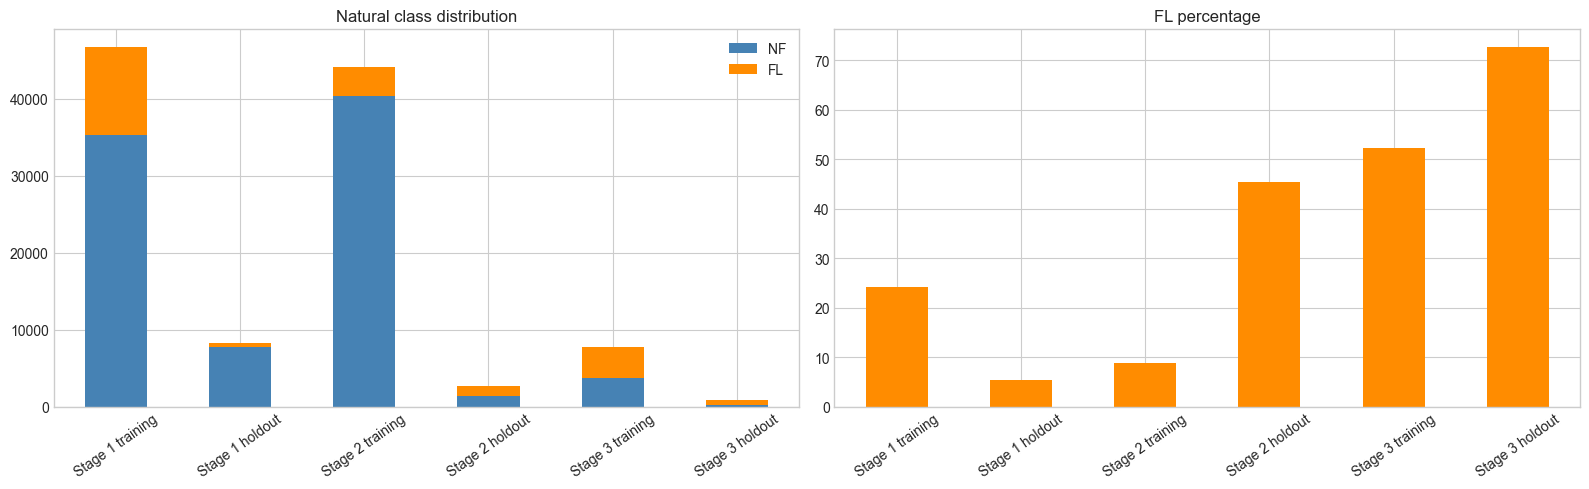

In [10]:
# Plot natural train and holdout distributions.
plot_data = split_summary[split_summary["role"].isin(["Training", "Holdout"])].set_index("dataset")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_data[["NF", "FL"]].plot(kind="bar", stacked=True, color=["steelblue", "darkorange"], ax=axes[0])
plot_data["FL_percent"].plot(kind="bar", color="darkorange", ax=axes[1])
axes[0].set_title("Natural class distribution"); axes[1].set_title("FL percentage")
for axis in axes:
    axis.set_xlabel(""); axis.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

In [11]:
# Future periods remain natural and are not used to find internal gaps.
future_summary = pd.DataFrame([summarize("Validation", blocks["Validation"]), summarize("Test", blocks["Test"])])
display(future_summary)

,dataset,start,end,samples,NF,FL,FL_percent
0,Validation,2024-07-01,2025-06-30 23:00:00,8480,3348,5132,60.518868
1,Test,2025-07-02,2026-07-31 23:00:00,9187,6044,3143,34.211386
